# Baseline with Mean and Ridge regression

In this notebook, we use mean prediction and ridge regression as our baselines. These methods should give us an estimate of how accurate our predictions are, and how we should improve from here onwards.

## Validation split

One interesting observation is that in our test data, the RENT_APPROVAL_DATE ranges from 2025 to 2026, whereas in train data is it 2021 - 2025. We are essentially trying to predict future rents from historical data, so we want a validation split that will mimic this forecasting sort of a behaviour.

In all our approaches, we follow the same split:
- Jan 2021 to March 2024 : train
- April 2024 to March 2025 : validation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("derived/train_cleaned_enriched.csv")
test = pd.read_csv("derived/test_cleaned_enriched.csv")

In [2]:
approval_dates = pd.to_datetime(train["RENT_APPROVAL_DATE"])
cutoff = (approval_dates.max().to_period("M").start_time - pd.DateOffset(months=12))

is_validation = approval_dates > cutoff
training_data = train.loc[~is_validation]
validation_data = train.loc[is_validation]

print(f"Training Data shape: {training_data.shape}, Validation Data shape: {validation_data.shape}")

Training Data shape: (114683, 21), Validation Data shape: (35158, 21)


## Mean prediction

How good is just predicting the mean of the target data for all input samples?

In [3]:
from sklearn.metrics import root_mean_squared_error

target = training_data["MONTHLY_RENT"]
val_target = validation_data["MONTHLY_RENT"]
mean_pred = target.mean()
rmse_train = root_mean_squared_error(target, [mean_pred] * len(target))
rmse_val = root_mean_squared_error(val_target, [mean_pred] * len(val_target))

print("Mean prediction:", mean_pred)
print("Train Baseline RMSE:", rmse_train)
print("Val Baseline RMSE:", rmse_val)


Mean prediction: 2595.431310656331
Train Baseline RMSE: 731.2325685748862
Val Baseline RMSE: 846.1543804685823


In [4]:
training_data.columns

Index(['TOWN', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'HDB_SUBZONE',
       'HDB_PLANNING_AREA', 'LOCATION_KEY', 'FLOOR_AREA_SQM',
       'LEASE_COMMENCE_DATE', 'HDB_LATITUDE', 'HDB_LONGITUDE',
       'HDB_YEAR_COMPLETED', 'NEAREST_MRT_KM', 'NEAREST_SCHOOL_KM',
       'NEAREST_MALL_KM', 'RENT_APPROVAL_DATE', 'APPROVAL_YEAR',
       'APPROVAL_MONTH', 'MONTH_INDEX', 'BUILDING_AGE', 'MONTHLY_RENT'],
      dtype='str')

## Preprocessing for Ridge Regression
Requires pandas and scikit-learn >= 1.3 (`TargetEncoder`).

1. Drop the column RENT_APPROVAL_DATE, since we have already extracted values from it.
2. One-hot encode: TOWN, FLAT_TYPE, FLAT_MODEL, HDB_PLANNING_AREA
3. Target encode the combined LOCATION_KEY identifier
4. Standardize numerical features
5. Keep one-hot indicators as 0/1 and MONTHLY_RENT in its original units.

    STREET and HDB_SUBZONE are not included since they are high-cardinality and somewhat related to location key.

See [scikit-learn TargetEncoder documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html).

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

TARGET = "MONTHLY_RENT"
NUMERIC_FEATURES = ['FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE', 
                    'HDB_LATITUDE', 'HDB_LONGITUDE', 'HDB_YEAR_COMPLETED', 
                    'NEAREST_MRT_KM', 'NEAREST_SCHOOL_KM','NEAREST_MALL_KM', 
                    'APPROVAL_YEAR', 'APPROVAL_MONTH', 'MONTH_INDEX', 'BUILDING_AGE']
ONEHOT_FEATURES = ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "HDB_PLANNING_AREA"]
BLOCK_FEATURES = ["LOCATION_KEY"]


def split_xy(data):
    """Separate the optional target and remove constant columns without mutating data."""
    X = data.drop(columns=[TARGET], errors="ignore").copy()
    y = data[TARGET].copy() if TARGET in data.columns else None
    return X, y


def make_preprocessor():
    """Return a fresh preprocessor; fit only on the training partition."""
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        # Keep all categories for Ridge; unseen categories become all-zero indicators.
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    block_pipeline = Pipeline([
        ("encode", TargetEncoder(target_type="continuous", smooth="auto",
                                 cv=5, shuffle=True, random_state=42)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, ONEHOT_FEATURES),
        ("block", block_pipeline, BLOCK_FEATURES),
    ], remainder="drop", sparse_threshold=0)


def preprocess(data, *, preprocessor=None):
    """Return (encoded X, optional y, fitted preprocessor).

    Omit preprocessor to fit on labeled training data (at least 5 rows).
    Pass the returned preprocessor to transform validation or test data.
    """
    X, y = split_xy(data)
    if preprocessor is None:
        if y is None:
            raise ValueError("Training data must contain MONTHLY_RENT.")
        if y.isna().any():
            raise ValueError("Training targets must not contain missing values.")
        if len(X) < 5:
            raise ValueError("TargetEncoder with cv=5 requires at least 5 training rows.")
        preprocessor = make_preprocessor()
        encoded = preprocessor.fit_transform(X, y)
    else:
        encoded = preprocessor.transform(X)
    encoded = pd.DataFrame(encoded, columns=preprocessor.get_feature_names_out(), index=X.index)
    return encoded, y, preprocessor

### Ridge regression model

There are no 'iterations' here as the solution is computed analytically (regularized linear regression solution).

In [6]:
model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("regressor", Ridge(alpha=0.0001)),
])

In [7]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reuse the chronological split created earlier: Apr 2024--Mar 2025
# is validation, and the earlier labeled rows are training data.
# The pipeline fits preprocessing only on training_data.
X_fit_raw, y_fit_raw = split_xy(training_data)
X_val_raw, y_val_raw = split_xy(validation_data)
model.fit(X_fit_raw, y_fit_raw)
val_predictions = model.predict(X_val_raw)

print(f"Training rows:   {len(X_fit_raw):,}")
print(f"Validation rows: {len(X_val_raw):,}")
print(f"Val MAE:  {mean_absolute_error(y_val_raw, val_predictions):,.2f}")
print(f"Val RMSE: {np.sqrt(mean_squared_error(y_val_raw, val_predictions)):,.2f}")
print(f"Val R²:   {r2_score(y_val_raw, val_predictions):.3f}")


Training rows:   114,683
Validation rows: 35,158
Val MAE:  466.41
Val RMSE: 620.08
Val R²:   0.115


/Users/apple/Documents/modules/CS5242/cs5242/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


In [8]:
X_all, y_all = split_xy(train)
X_test_raw, _ = split_xy(test)

model.fit(X_all, y_all)
test_predictions = model.predict(X_test_raw)

submission = pd.DataFrame({
    "Id": range(len(test_predictions)),
    "Predicted": test_predictions,
})
submission.to_csv("predictions/ridge_regression_submission.csv", index=False)

/Users/apple/Documents/modules/CS5242/cs5242/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


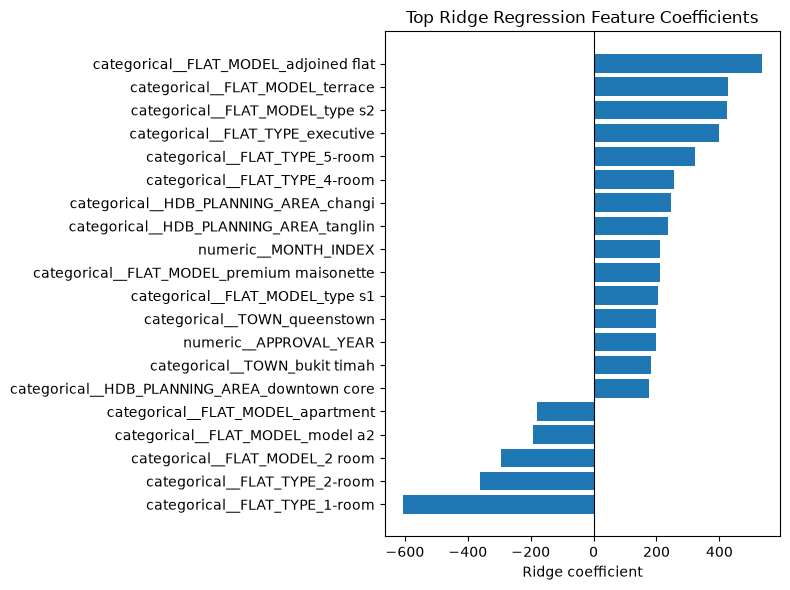

<Figure size 640x480 with 0 Axes>

In [9]:
preprocessor = model.named_steps["preprocessor"]
regressor = model.named_steps["regressor"]

feature_names = preprocessor.get_feature_names_out()

coef_df = pd.DataFrame({"feature": feature_names, "coefficient": regressor.coef_})

coef_df["absolute_coefficient"] = coef_df["coefficient"].abs()

top_coefficients = (
    coef_df.sort_values("absolute_coefficient", ascending=False)
           .head(20)
           .sort_values("coefficient")
)

plt.figure(figsize=(8, 6))
plt.barh(
    top_coefficients["feature"],
    top_coefficients["coefficient"]
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Ridge coefficient")
plt.title("Top Ridge Regression Feature Coefficients")
plt.tight_layout()
plt.show()
plt.savefig("plots/ridge_regression_coeff.png", dpi=300, bbox_inches="tight")

We can see that FLAT_TYPE, FLAT_MODEL and APPROVAL_YEAR are playing an important role in predictions.

## Random Forest regression

Ridge regression models the target as a weighted sum of the input features. This is useful as a simple, interpretable baseline, but it assumes that feature effects are additive and approximately linear. 

A Random Forest moves to a tree-based approach: each decision tree learns splits and interactions, while bagging averages many trees trained on bootstrap samples. This can capture relationships such as location- or size-dependent rent thresholds that Ridge may miss, while averaging reduces the variance of any one tree.

The same chronological split is retained: January 2021-March 2024 for training and April 2024-March 2025 for validation. The Random Forest preprocessor is fitted only on the training partition.

In [10]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# Trees do not require feature scaling, so this preprocessor imputes numeric
# values, one-hot encodes low-cardinality categories, and target-encodes
# LOCATION_KEY. It is fitted on training data only.
rf_numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
])
rf_categorical_pipeline = Pipeline([
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
rf_location_pipeline = Pipeline([
    ("encode", TargetEncoder(target_type="continuous", smooth="auto",
                                 cv=5, shuffle=True, random_state=42)),
])
rf_preprocessor = ColumnTransformer([
    ("numeric", rf_numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", rf_categorical_pipeline, ONEHOT_FEATURES),
    ("location", rf_location_pipeline, BLOCK_FEATURES),
], remainder="drop", sparse_threshold=0)

X_rf_train = rf_preprocessor.fit_transform(X_fit_raw, y_fit_raw)
X_rf_val = rf_preprocessor.transform(X_val_raw)
rf_feature_names = rf_preprocessor.get_feature_names_out()

/Users/apple/Documents/modules/CS5242/cs5242/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Random Forest metrics
Train RMSE: 429.41
Val RMSE:   476.79
Val MAE:    355.38
Val R²:     0.477


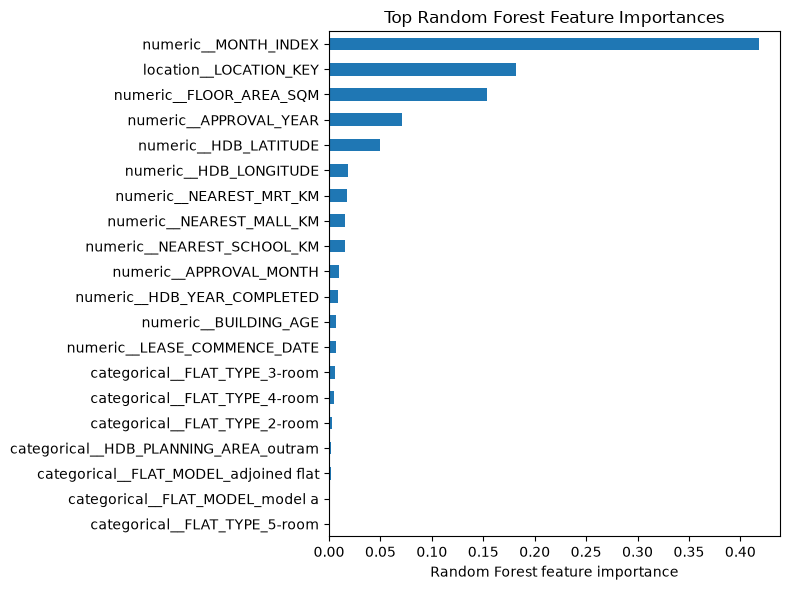

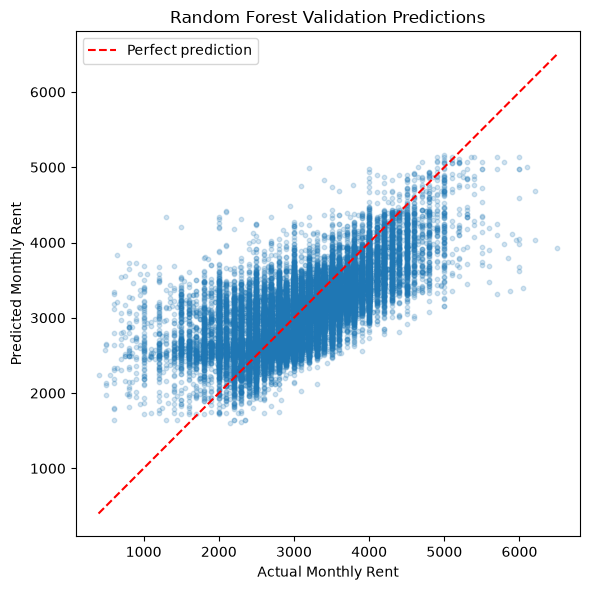

<Figure size 640x480 with 0 Axes>

In [11]:
# FLAML-selected hyperparameters: 189 trees (reduces variance); max_depth (limits tree complexity)
# min_samples_leaf stabilizes predictions for small groups;
# max_features decorrelates trees; n_jobs=-1 uses all available cores.
random_forest = RandomForestRegressor(
    n_estimators=189,
    max_depth=14,
    min_samples_leaf=8,
    max_features=0.8193776787903664,
    random_state=42,
    n_jobs=-1,
)
random_forest.fit(X_rf_train, y_fit_raw)
rf_train_predictions = random_forest.predict(X_rf_train)
rf_val_predictions = random_forest.predict(X_rf_val)

print("Random Forest metrics")
print(f"Train RMSE: {root_mean_squared_error(y_fit_raw, rf_train_predictions):,.2f}")
print(f"Val RMSE:   {root_mean_squared_error(y_val_raw, rf_val_predictions):,.2f}")
print(f"Val MAE:    {mean_absolute_error(y_val_raw, rf_val_predictions):,.2f}")
print(f"Val R²:     {r2_score(y_val_raw, rf_val_predictions):.3f}")

# Plot the most influential transformed features.
importance = (
    pd.Series(random_forest.feature_importances_, index=rf_feature_names)
      .sort_values(ascending=False)
      .head(20)
      .sort_values()
)
plt.figure(figsize=(8, 6))
importance.plot(kind="barh")
plt.xlabel("Random Forest feature importance")
plt.title("Top Random Forest Feature Importances")
plt.tight_layout()
plt.show()

# Plot validation predictions against observed rents.
plt.figure(figsize=(6, 6))
plt.scatter(y_val_raw, rf_val_predictions, alpha=0.2, s=10)
limits = [min(y_val_raw.min(), rf_val_predictions.min()),
          max(y_val_raw.max(), rf_val_predictions.max())]
plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlabel("Actual Monthly Rent")
plt.ylabel("Predicted Monthly Rent")
plt.title("Random Forest Validation Predictions")
plt.legend()
plt.tight_layout()
plt.show()
plt.savefig("plots/random_forest_features.png", dpi=300, bbox_inches="tight")

### Loss variation according to number of trees:
We see how adding more trees affects the loss function.

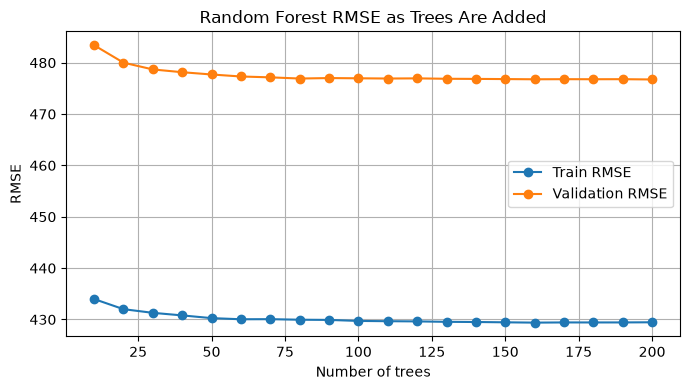

In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
import matplotlib.pyplot as plt

tree_counts = range(10, 201, 10)
train_rmse = []
val_rmse = []

rf_curve = RandomForestRegressor(
    warm_start=True,
    max_depth=14,
    min_samples_leaf=8,
    max_features=0.8193776787903664,
    random_state=42,
    n_jobs=-1
)

for n_trees in tree_counts:
    rf_curve.set_params(n_estimators=n_trees)
    rf_curve.fit(X_rf_train, y_fit_raw)

    train_pred = rf_curve.predict(X_rf_train)
    val_pred = rf_curve.predict(X_rf_val)

    train_rmse.append(root_mean_squared_error(y_fit_raw, train_pred))
    val_rmse.append(root_mean_squared_error(y_val_raw, val_pred))

plt.figure(figsize=(7, 4))
plt.plot(tree_counts, train_rmse, marker="o", label="Train RMSE")
plt.plot(tree_counts, val_rmse, marker="o", label="Validation RMSE")
plt.xlabel("Number of trees")
plt.ylabel("RMSE")
plt.title("Random Forest RMSE as Trees Are Added")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

There is a slight variation in RMSE, but not huge. This proves, empirically to some extent that Random forest doesn't overfit if we increase the number of trees!

In [13]:
# Refit Random Forest on all labeled rows before predicting the test set.
# This happens only after validation/model comparison is complete.
X_all_raw, y_all = split_xy(train)
X_test_raw, _ = split_xy(test)

rf_final_preprocessor = ColumnTransformer([
    ("numeric", rf_numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", rf_categorical_pipeline, ONEHOT_FEATURES),
    ("location", rf_location_pipeline, BLOCK_FEATURES),
], remainder="drop", sparse_threshold=0)
X_rf_all = rf_final_preprocessor.fit_transform(X_all_raw, y_all)
X_rf_test = rf_final_preprocessor.transform(X_test_raw)

rf_final_model = RandomForestRegressor(
    n_estimators=189,
    max_depth=14,
    min_samples_leaf=8,
    max_features=0.8193776787903664,
    random_state=42,
    n_jobs=-1,
)
rf_final_model.fit(X_rf_all, y_all)
rf_test_predictions = rf_final_model.predict(X_rf_test)

rf_submission = pd.DataFrame({
    "Id": np.arange(len(rf_test_predictions)),
    "Predicted": rf_test_predictions,
})
rf_submission.to_csv("predictions/random_forest_submission.csv", index=False)
print(f"Saved random_forest_submission.csv ({len(rf_submission):,} rows)")
rf_submission.head()

/Users/apple/Documents/modules/CS5242/cs5242/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Saved random_forest_submission.csv (50,000 rows)


,Id,Predicted
0,0,2823.020200
1,1,3612.854211
2,2,3129.036589
3,3,3092.653532
4,4,3327.092977


# CatBoost regression

Ridge is a useful linear baseline, and Random Forest captures nonlinear splits through bagging. 

CatBoost is added as a boosting model: it builds trees sequentially, with each new tree focusing on errors left by the previous trees. This often performs well when rent depends on nonlinear effects and interactions, such as combinations of location, floor area, flat model, and market time. CatBoost also handles **categorical variables natively**, avoiding a very large one-hot representation.

Only light preprocessing is needed. The validation split remains April 2024-March 2025, matching Ridge and Random Forest.

Hyperparameters use the FLAML-selected settings: depth=7, learning_rate=0.0718104404496359, l2_leaf_reg=10.104124680450155, and iterations=1094 (the selected tree count). The existing early-stopping patience of 100 is retained.

The learning curve below shows training and validation RMSE by iteration. Additional diagnostics include validation predicted-versus-actual values and CatBoost feature importance. Because the validation set is used for early stopping and comparison, its score is a model-selection estimate.

In [14]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error

CATBOOST_ALL_FEATURES = ["FLOOR_AREA_SQM","LEASE_COMMENCE_DATE","HDB_LATITUDE",
    "HDB_LONGITUDE","HDB_YEAR_COMPLETED","NEAREST_MRT_KM","NEAREST_SCHOOL_KM",
    "NEAREST_MALL_KM","APPROVAL_YEAR","APPROVAL_MONTH","MONTH_INDEX","BUILDING_AGE",
    "TOWN","FLAT_TYPE","FLAT_MODEL","HDB_PLANNING_AREA","LOCATION_KEY",
]
CATBOOST_CATEGORICAL = ["TOWN","FLAT_TYPE","FLAT_MODEL","HDB_PLANNING_AREA","LOCATION_KEY"]

def make_catboost_features(data):
    """Build target-independent features while preserving input row order."""

    # Data has already been cleaned; ensure CatBoost categorical columns are strings.
    X = data[CATBOOST_ALL_FEATURES].copy()
    return X


X_cb_train = make_catboost_features(training_data)
y_cb_train = pd.to_numeric(training_data[TARGET], errors="raise")

X_cb_val = make_catboost_features(validation_data)
y_cb_val = pd.to_numeric(validation_data[TARGET], errors="raise")

X_cb_test = make_catboost_features(test)

print(f"Train: {X_cb_train.shape}")
print(f"Validation: {X_cb_val.shape}")

Train: (114683, 17)
Validation: (35158, 17)


In [15]:
# Best CatBoost parameters from Models_FLAML_tuning.ipynb (1094 selected trees).
CB_PARAMS = dict(
    loss_function="RMSE",
    eval_metric="RMSE",
    depth=7,
    learning_rate=0.0718104404496359,
    l2_leaf_reg=10.104124680450155,
    random_seed=42,
    thread_count=4,
    allow_writing_files=False,
)
catboost_validation_model = CatBoostRegressor(iterations=1094, **CB_PARAMS)
catboost_validation_model.fit(
    X_cb_train, y_cb_train,
    cat_features=CATBOOST_CATEGORICAL,
    eval_set=(X_cb_val, y_cb_val),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=200,
)
cb_val_predictions = catboost_validation_model.predict(X_cb_val)
cb_best_iterations = catboost_validation_model.tree_count_
print(f"Selected number of trees: {cb_best_iterations}")

0:	learn: 705.5352214	test: 813.3009325	best: 813.3009325 (0)	total: 86.1ms	remaining: 1m 34s
200:	learn: 478.1289824	test: 476.9070470	best: 476.9069939 (199)	total: 4.17s	remaining: 18.5s
400:	learn: 473.4854045	test: 473.2782915	best: 473.2782915 (400)	total: 8.79s	remaining: 15.2s
600:	learn: 469.6777675	test: 471.9723036	best: 471.9707357 (595)	total: 13.6s	remaining: 11.2s
800:	learn: 466.3999820	test: 471.1947602	best: 471.1929223 (799)	total: 18.7s	remaining: 6.86s
1000:	learn: 463.7169411	test: 470.9405589	best: 470.9366214 (997)	total: 23.8s	remaining: 2.21s
1093:	learn: 462.4760268	test: 470.8198008	best: 470.8198008 (1093)	total: 26.2s	remaining: 0us

bestTest = 470.8198008
bestIteration = 1093

Selected number of trees: 1094


In [16]:
# Refit using all labels and the tree count selected during validation.
catboost_final_model = CatBoostRegressor(iterations=cb_best_iterations, **CB_PARAMS)

X_cb = make_catboost_features(train)
y_cb = pd.to_numeric(train[TARGET], errors="raise")

catboost_final_model.fit(X_cb, y_cb, cat_features=CATBOOST_CATEGORICAL, verbose=200)
catboost_test_predictions = catboost_final_model.predict(X_cb_test)

catboost_submission = pd.DataFrame({
    "Id": np.arange(len(test)),
    "Predicted": catboost_test_predictions,
})
catboost_submission.to_csv("predictions/catboost_submission.csv", index=False)
print(f"Saved catboost_submission.csv ({len(catboost_submission):,} rows)")
catboost_submission.head()

0:	learn: 722.0491399	total: 26ms	remaining: 28.4s
200:	learn: 477.0594540	total: 5.21s	remaining: 23.2s
400:	learn: 472.5019284	total: 11.4s	remaining: 19.6s
600:	learn: 468.7155174	total: 17.4s	remaining: 14.3s
800:	learn: 465.8442545	total: 23.7s	remaining: 8.67s
1000:	learn: 463.3406395	total: 30s	remaining: 2.79s
1093:	learn: 462.3102230	total: 32.8s	remaining: 0us
Saved catboost_submission.csv (50,000 rows)


,Id,Predicted
0,0,2807.490846
1,1,3676.257181
2,2,3227.132376
3,3,3149.565439
4,4,3323.932945


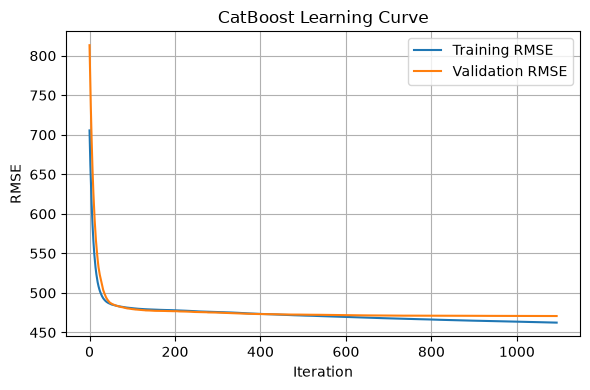

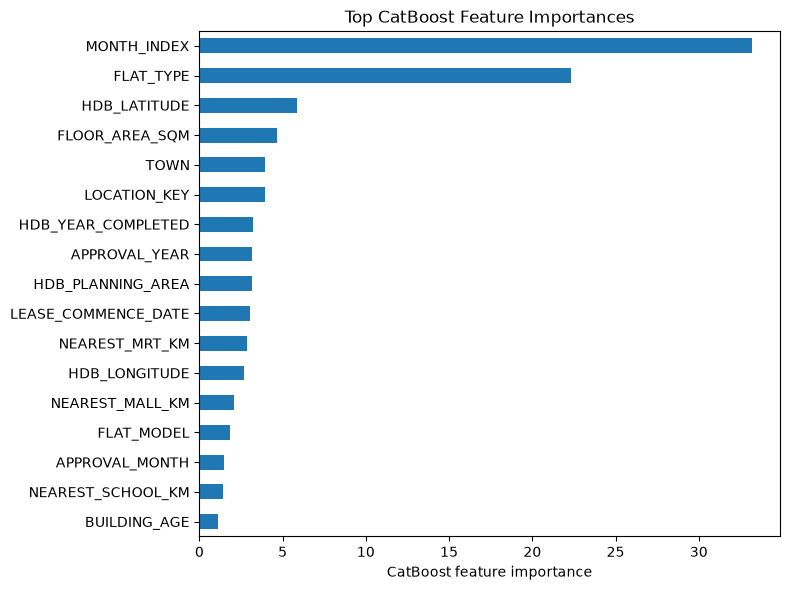

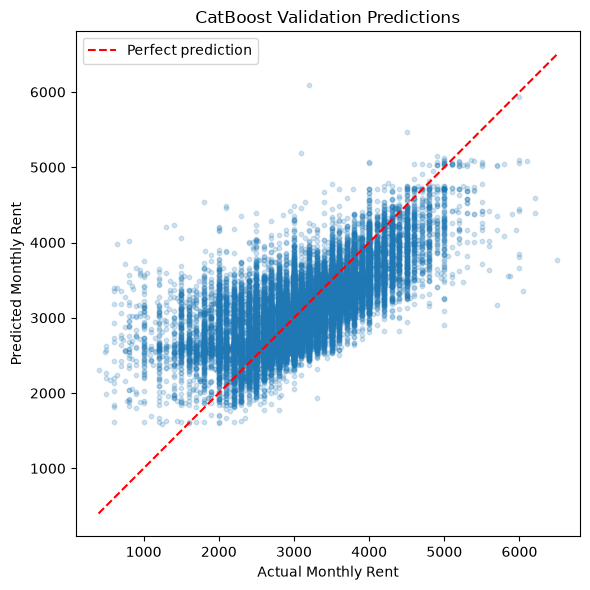

In [17]:
import matplotlib.pyplot as plt

results = catboost_validation_model.get_evals_result()

plt.figure(figsize=(6, 4))
plt.plot(results["learn"]["RMSE"], label="Training RMSE")
plt.plot(results["validation"]["RMSE"], label="Validation RMSE")
plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("CatBoost Learning Curve")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# CatBoost feature importance for the validation model.
catboost_importance = (
    pd.Series(catboost_validation_model.get_feature_importance(), index=X_cb.columns)
      .sort_values(ascending=False)
      .head(20)
      .sort_values()
)
plt.figure(figsize=(8, 6))
catboost_importance.plot(kind="barh")
plt.xlabel("CatBoost feature importance")
plt.title("Top CatBoost Feature Importances")
plt.tight_layout()
plt.show()

# Validation predictions versus observed rents.
cb_actual = y_cb_val
plt.figure(figsize=(6, 6))
plt.scatter(cb_actual, cb_val_predictions, alpha=0.2, s=10)
limits = [min(cb_actual.min(), cb_val_predictions.min()),
          max(cb_actual.max(), cb_val_predictions.max())]
plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlabel("Actual Monthly Rent")
plt.ylabel("Predicted Monthly Rent")
plt.title("CatBoost Validation Predictions")
plt.legend()
plt.tight_layout()
plt.show()

### Other boosting methods:

We have other well-known methods such as XGBoost, so we compare on-paper if they might fit our scenario better and then proceed with them. Compared XGBoost and CatBoost with the help of GPT 5.6:

| Aspect | XGBoost | CatBoost |
|---|---|---|
| Core method | Gradient boosting with regularized trees | Gradient boosting with ordered boosting techniques |
| Categorical features | Supports them in newer versions with `enable_categorical=True`, but requires pandas categorical types and appropriate settings; one-hot/target encoding is also common. | Designed to handle categorical features natively using statistics and category combinations. |
| Preprocessing | Usually needs more feature preparation | Usually needs less preprocessing |
| Strength | Excellent for engineered numerical features and sparse/encoded matrices | Particularly convenient for mixed numerical and high-cardinality categorical data |
| Tuning | Many important parameters and often more tuning effort | Often performs well with reasonable defaults |

Considering our dataset that has a mix of imp categorical and numerical features, CatBoost is well suited.
Further, we move on to error analysis, i.e. which groups of samples might be contributing most to errors and how we can work towards reducing it. We will revisit EDA knowledge.